# 03 - Benchmarks

Compares LimiX-2, LightGBM, XGBoost, logistic regression and the heuristic scorecard on the public
and synthetic datasets with stratified cross-validation.

The protocol is deliberately conservative:

* the same folds for every model;
* preprocessing fitted inside each training fold;
* LimiX receives only the training fold as its in-context reference set;
* AUC, KS, PR-AUC, Brier and log loss are reported.

The Polish benchmark is omitted here for runtime; run the CLI for all four datasets.


In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from opencashflow.benchmark import run_benchmark
from opencashflow.data.loaders import list_datasets

pd.set_option("display.width", 160)

## 1. Dataset registry

In [2]:
list_datasets()

,name,title,rows,features,default_rate,license,doi
0,polish,Polish Companies Bankruptcy,"7,027 (1year) to 10,503 (3year)",64,3.9%-6.9% depending on horizon,CC BY 4.0,10.24432/C5F600
1,german,Statlog (German Credit Data),"1,000",20 attributes,30.0%,CC BY 4.0,10.24432/C5NC77
2,bangladesh_sme,Structured Data Suffices: SME Credit Risk in B...,"1,200",27 columns including text narratives,25.25%,"CC BY 4.0 (data), MIT (code)",10.5281/zenodo.18525278
3,synthetic,OpenCashFlow synthetic SME portfolio,configurable,151 cash-flow features,"configurable, 12% by default",Apache-2.0 (generated data),


## 2. Run the benchmark

This uses three datasets, three folds, and one LimiX pipeline. Expect a couple of minutes on CPU. If LimiX is unavailable, the harness skips it with a warning.

In [3]:
root = Path.cwd()
if not (root / "pyproject.toml").exists() and (root.parent / "pyproject.toml").exists():
    root = root.parent

report = run_benchmark(
    datasets=["synthetic", "german", "bangladesh_sme"],
    models=["heuristic", "logistic", "lightgbm", "xgboost", "limix"],
    cv=3,
    seed=42,
    synthetic_companies=160,
    synthetic_months=18,
    limix_pipelines=1,
    output_dir=root / "benchmarks" / "results" / "notebook",
    verbose=True,
)
report.summary.round(3)

[dataset] synthetic


  [model] heuristic
  [model] logistic


  [model] lightgbm


  [model] xgboost


  [model] limix


arch_version=2.0 -> inference.v2_0.predictor (inference.v2_0.predictor)
Mixed precision is not supported for CPU inference, so it has been automatically disabled
use limix v2.0


... (8 outputs left out)

  [model] xgboost


  [model] limix


arch_version=2.0 -> inference.v2_0.predictor (inference.v2_0.predictor)
Mixed precision is not supported for CPU inference, so it has been automatically disabled
use limix v2.0


,dataset,model,n,n_features,default_rate,roc_auc,roc_auc_std,ks,pr_auc,brier,log_loss,fit_seconds,predict_seconds
0,bangladesh_sme,limix,1200,19,0.252,0.928,0.028,0.716,0.831,0.092,0.292,0.024,12.338
1,bangladesh_sme,logistic,1200,19,0.252,0.895,0.020,0.635,0.768,0.133,0.410,0.023,0.006
2,bangladesh_sme,lightgbm,1200,19,0.252,0.894,0.025,0.633,0.757,0.112,0.352,0.425,0.008
3,bangladesh_sme,xgboost,1200,19,0.252,0.893,0.021,0.655,0.739,0.113,0.355,0.513,0.010
4,german,limix,1000,20,0.300,0.804,0.032,0.484,0.643,0.159,0.483,0.021,10.307
5,german,xgboost,1000,20,0.300,0.781,0.031,0.445,0.610,0.175,0.532,0.762,0.014
6,german,logistic,1000,20,0.300,0.779,0.031,0.444,0.591,0.192,0.566,0.136,0.035
7,german,lightgbm,1000,20,0.300,0.769,0.039,0.439,0.598,0.180,0.546,1.613,0.013
8,synthetic,heuristic,160,151,0.087,0.855,0.092,0.751,0.516,0.066,0.240,0.000,0.003
9,synthetic,limix,160,151,0.087,0.805,0.130,0.695,0.423,0.082,0.287,0.179,37.051


## 3. Ranking by dataset

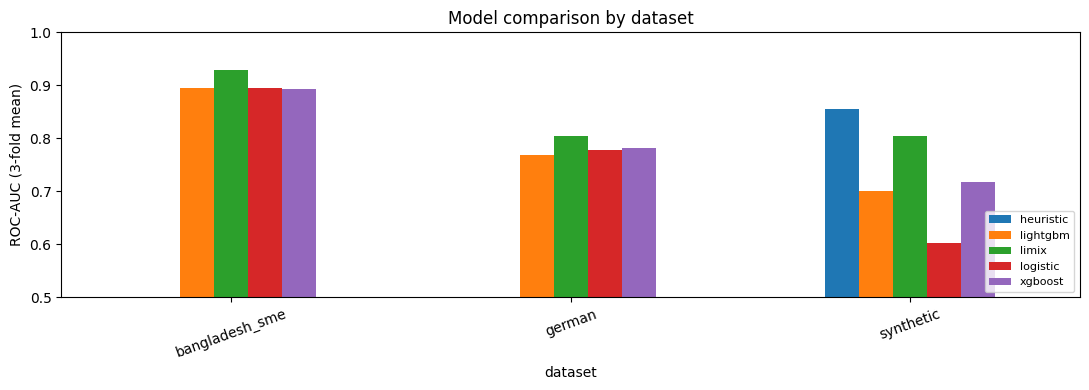

model,heuristic,lightgbm,limix,logistic,xgboost
dataset,,,,,
bangladesh_sme,NaN,0.894,0.928,0.895,0.893
german,NaN,0.769,0.804,0.779,0.781
synthetic,0.855,0.701,0.805,0.603,0.717


In [4]:
pivot = report.summary.pivot(index="dataset", columns="model", values="roc_auc").sort_index()
fig, ax = plt.subplots(figsize=(11, 4))
pivot.plot(kind="bar", ax=ax)
ax.set_ylabel("ROC-AUC (3-fold mean)")
ax.set_title("Model comparison by dataset")
ax.set_ylim(0.5, 1.0)
ax.legend(loc="lower right", fontsize=8)
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()
pivot.round(3)

## 4. Calibration matters too

AUC only measures ranking. Brier score penalises confident wrong probabilities.

In [5]:
brier = report.summary.pivot(index="dataset", columns="model", values="brier").sort_index()
brier.round(3)

model,heuristic,lightgbm,limix,logistic,xgboost
dataset,,,,,
bangladesh_sme,NaN,0.112,0.092,0.133,0.113
german,NaN,0.180,0.159,0.192,0.175
synthetic,0.066,0.097,0.082,0.109,0.095


## 5. Dataset notes

The Bangladesh loader drops `missed_payment_last_12m` because it is an exact copy of the target. German and Polish are tabular accounting/application datasets, not transaction ledgers.

In [6]:
from opencashflow.data.loaders import load_dataset

for name in ["german", "bangladesh_sme"]:
    bundle = load_dataset(name)
    print(bundle.summary())
    print("  leakage columns dropped:", bundle.metadata.get("dropped_leakage_columns", []))
    print("  categorical features:", len(bundle.categorical_features))

german: 1,000 rows x 20 features, default rate 30.00%, source UCI Machine Learning Repository, licence CC BY 4.0
  leakage columns dropped: []
  categorical features: 13
bangladesh_sme: 1,200 rows x 19 features, default rate 25.25%, source Zenodo, licence CC BY 4.0 (data), MIT (code)
  leakage columns dropped: ['missed_payment_last_12m']
  categorical features: 9


## 6. Interpretation guardrails

* These are small public datasets. Fold variance is real; read `roc_auc_std` in the results table.
* The synthetic portfolio is the only transaction-level benchmark and its labels are generated.
* LimiX ran with one pipeline on CPU. A 32-member GPU run is not comparable.
* Do not claim state of the art from this notebook. Use it to compare implementations, features and
  preprocessing under a shared protocol.

Saved outputs are in `benchmarks/results/notebook/`.
